In [ ]:
#The usual preamble
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.dates import DateFormatter
import cv2
from moviepy.editor import *


import seaborn as sns
import tensorflow as tf

#for your homework
np.random.seed(37509116)
tf.random.set_seed(37509116)


/usr/local/lib/python3.12/dist-packages/moviepy/config_defaults.py:47: SyntaxWarning: invalid escape sequence '\P'
  IMAGEMAGICK_BINARY = r"C:\Program Files\ImageMagick-6.8.8-Q16\magick.exe"
/usr/local/lib/python3.12/dist-packages/moviepy/video/io/ffmpeg_reader.py:294: SyntaxWarning: invalid escape sequence '\d'
  lines_video = [l for l in lines if ' Video: ' in l and re.search('\d+x\d+', l)]
/usr/local/lib/python3.12/dist-packages/moviepy/video/io/ffmpeg_reader.py:367: SyntaxWarning: invalid escape sequence '\d'
  rotation_lines = [l for l in lines if 'rotate          :' in l and re.search('\d+$', l)]
/usr/local/lib/python3.12/dist-packages/moviepy/video/io/ffmpeg_reader.py:370: SyntaxWarning: invalid escape sequence '\d'
  match = re.search('\d+$', rotation_line)
  if event.key is 'enter':



In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
#CHOC Childrens video from last time
video_filename = '/content/drive/MyDrive/Colab Notebooks/CHOCVideo2.mov'
video_reader = cv2.VideoCapture(video_filename)


In [ ]:
video_reader.read()

(True,
 array([[[ 79,  80,  85],
         [ 77,  78,  83],
         [ 78,  74,  84],
         ...,
         [ 97,  95,  57],
         [ 95,  94,  74],
         [107, 106,  86]],
 
        [[ 86,  87,  92],
         [ 87,  88,  93],
         [ 94,  90, 100],
         ...,
         [ 90,  88,  50],
         [ 88,  87,  67],
         [101, 100,  80]],
 
        [[101, 111, 115],
         [103, 113, 117],
         [106, 114, 123],
         ...,
         [ 84,  84,  55],
         [ 83,  85,  69],
         [ 95,  97,  81]],
 
        ...,
 
        [[ 67,  67,  65],
         [ 67,  67,  65],
         [ 69,  66,  65],
         ...,
         [119, 144, 145],
         [123, 145, 147],
         [124, 146, 148]],
 
        [[ 53,  43,  43],
         [ 53,  43,  43],
         [ 55,  43,  43],
         ...,
         [117, 142, 143],
         [118, 140, 142],
         [121, 143, 145]],
 
        [[ 35,  25,  25],
         [ 35,  25,  25],
         [ 37,  25,  25],
         ...,
         [121, 146, 1

Width = 640, Height = 360, Colors = 3


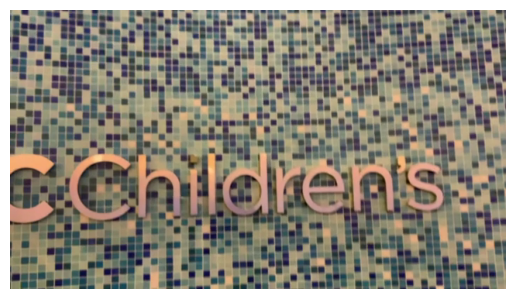

In [ ]:
_, bgr_frame = video_reader.read()
rgb_frame = cv2.cvtColor(bgr_frame, cv2.COLOR_BGR2RGB)  #convert to RGB order for processing
plt.imshow(rgb_frame)
plt.axis('off')
orig_width = bgr_frame.shape[1]
orig_height = bgr_frame.shape[0]
ncolors = bgr_frame.shape[2]
image_width = 128
image_height = int(orig_height * image_width / orig_width)  #proportional scaling to preserve aspect ratio
print(f'Width = {orig_width}, Height = {orig_height}, Colors = {ncolors}')


In [ ]:
#this time we are going to convert to grayscale, and we will only use one image at a time
#  we do not need to concatenate x(t) and x(t+1) because we will let the LSTM network handle the changes with time.
frames_list = []
nframes = 0
cvt_gray = [0.2989, 0.5870, 0.1140]   # these are standard ratios for converting RGB to grayscale

while True:
  success, bgr_frame = video_reader.read()
  if not success:
     break
  rgb_frame = cv2.cvtColor(bgr_frame, cv2.COLOR_BGR2RGB)   #RGB color conversion
  gray_frame = np.dot(rgb_frame, cvt_gray)  #dot() operator works on the last dimension
  resized_frame = cv2.resize(gray_frame, (image_width, image_height))  #resize and smooth to make smaller
  normalized_frame = resized_frame / 255
  frames_list.append(normalized_frame)
  nframes +=1
video_reader.release()
print(f'Read {nframes} frames')

Read 1845 frames


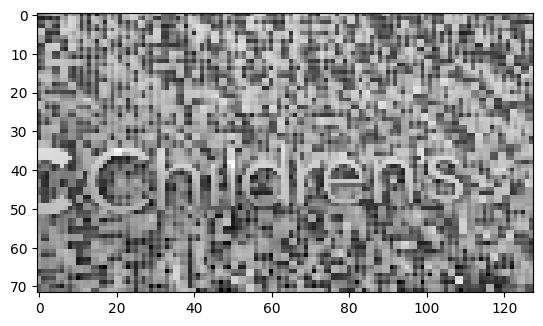

In [ ]:
plt.imshow(frames_list[1], cmap=plt.get_cmap('gray'));

In [ ]:
#same gyro data as before
dfGyro = pd.read_csv('/content/drive/MyDrive/Colab Notebooks/gyro.csv')
dfGyro = dfGyro.rename(columns={
    'Time' : 't',
    ' Rotation Rate (X)' : 'wx',
    ' Rotation Rate (Y)' : "wy",
    ' Rotation Rate (Z)' : "wz"})   #data record at 30Hz, which is same as video frame rate
dfGyro['t'] = dfGyro['t'] - dfGyro['t'][0]  #set the initial time to be zero
dfGyro

,t,wx,wy,wz
0,0.00000,0.099509,-0.028426,-0.044815
1,0.03334,-0.003392,0.011171,-0.077364
2,0.06667,0.095900,-0.036499,-0.057394
3,0.10000,0.339899,-0.068623,0.027582
4,0.13334,0.290086,0.027662,0.018464
...,...,...,...,...
1832,61.05606,0.019010,0.038634,-0.068281
1833,61.08941,0.092307,-0.020316,0.006578
1834,61.12276,0.033317,-0.014301,0.038383
1835,61.15614,-0.001969,-0.004178,-0.023021


(1837, 2)

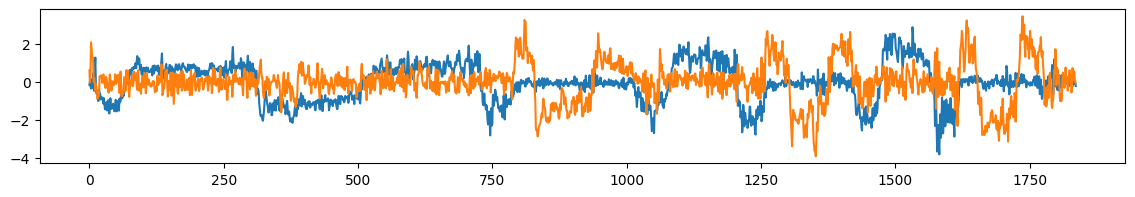

In [ ]:
#predict both the horizontal and vertical gyro
desired_output_horizontal = dfGyro['wy'] / dfGyro['wy'].std()   #normalize so the network can learn
desired_output_vertical = dfGyro['wx'] / dfGyro['wx'].std()
desired_output = np.vstack((desired_output_horizontal.values, desired_output_vertical.values)).transpose()  #make column-wise

#make a list of the video frames that has the timestamps
nTimes, nOutputs = desired_output.shape  #in this case, the gyro data is slightly shorter than the video data
frames_list = frames_list[:nTimes]       #trim the video to be exactly the length of the gyro
      #to be safe, I checked first that the video length and gyro data length were the same; never trust the stated frame rate
imSeries = pd.Series(data=frames_list, index=dfGyro['t'])   #assigns timestamps to the video data in case we need that

plt.figure(figsize=(14,2))
plt.plot(desired_output);   #the gyro data are quite noisy.  I don't both filtering it; the network has to figure this out.
desired_output.shape


In [ ]:
from tensorflow.python.keras.engine.base_layer_utils import uses_keras_history
from tensorflow.keras.utils import plot_model
from tensorflow.keras.models import Sequential, Model
from tensorflow.keras.layers import Permute, AveragePooling2D, Concatenate
from tensorflow.keras.layers import Dense, Flatten, Reshape, Conv2D, LayerNormalization, SimpleRNN
from tensorflow.keras.layers import MaxPooling2D, GlobalAveragePooling2D, ConvLSTM2D, LSTM, Input
from tensorflow.keras.preprocessing.sequence import TimeseriesGenerator
from tensorflow.keras.callbacks import EarlyStopping


In [ ]:
#generator for image prediction
early_stop = EarlyStopping(monitor='val_loss',patience=2)

predict_length = 5
batch_size = 1
training_set_size = int(0.9 * nTimes)
test_set_size = nTimes - training_set_size
gen1 = TimeseriesGenerator(frames_list, frames_list, length = predict_length, batch_size=batch_size)
training_gen1 = TimeseriesGenerator(frames_list[:training_set_size], frames_list[:training_set_size], length = predict_length, batch_size=batch_size)
validation_gen1 = TimeseriesGenerator(frames_list[:-test_set_size], frames_list[:-test_set_size], length = predict_length, batch_size=batch_size)

#note the shape of the output:  (batch_size, predict_length, height, width, colorchannels)
gen1[100][0].shape

(1, 5, 72, 128)

Model: "model1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 5, 72, 128, 1)  │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_lstm2d (ConvLSTM2D)        │ (None, 72, 128, 10)    │        11,040 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 72, 128, 1)     │            11 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,051 (43.17 KB)

 Trainable params: 11,051 (43.17 KB)

 Non-trainable params: 0 (0.00 B)

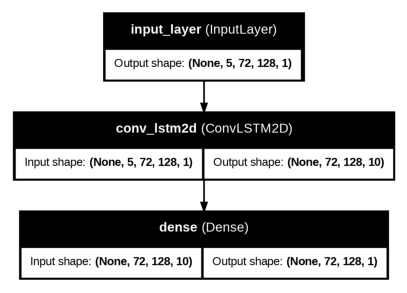

In [ ]:
#build the network

len_conv_window = 5            #how many points in the convolution kernel in both x and y directions
n_conv_units = 10              #how many different convolution kernels h_i
n_sensors = 1                  #this is now grayscale, so only one channel
n_time_images = predict_length
n_batch = 1

#this time we will use the standard Keras interface.  each layer is linked to the one below programmatically
input_layer = Input(shape=(n_time_images, image_height, image_width, n_sensors), name='input_layer')
#convLSTM2D has n_conv_units outputs for each pixel in the image.  padding="same" means output image is same size as input
# channels_last data format says this was in the format height, width channels (not channels, height, width)).
time_space_layer = ConvLSTM2D(filters=n_conv_units, kernel_size=(5,5), data_format='channels_last',
                              padding='same', return_sequences=False, activation='sigmoid')(input_layer)
#dense layer takes all n_conv_units values at each pixel and combines to a single value to match the output image
top_layer = Dense(units=1, activation='linear')(time_space_layer)
output_layer = top_layer

model1 = Model(inputs = input_layer, outputs = output_layer, name ='model1')  #have to explicitly tell it the inputs and outputs
model1.compile(optimizer='adam', loss='mse')
model1.summary()

#plot_model(model1, show_shapes = True, show_layer_names = True)

plot_model(model1, to_file='model.png', show_shapes=True, show_layer_names=True)

plt.figure(figsize=(5,5))  # Adjust the figure size as needed
plt.imshow(plt.imread('model.png'))
plt.axis('off')
plt.show()



  self._warn_if_super_not_called()



Epoch 1/5
1648/1648 ━━━━━━━━━━━━━━━━━━━━ 24s 12ms/step - loss: 0.0174 - val_loss: 0.0130
Epoch 2/5
1648/1648 ━━━━━━━━━━━━━━━━━━━━ 17s 11ms/step - loss: 0.0129 - val_loss: 0.0127
Epoch 3/5
1648/1648 ━━━━━━━━━━━━━━━━━━━━ 19s 11ms/step - loss: 0.0128 - val_loss: 0.0126
Epoch 4/5
1648/1648 ━━━━━━━━━━━━━━━━━━━━ 19s 11ms/step - loss: 0.0125 - val_loss: 0.0128
Epoch 5/5
1648/1648 ━━━━━━━━━━━━━━━━━━━━ 18s 11ms/step - loss: 0.0128 - val_loss: 0.0126


<Axes: >

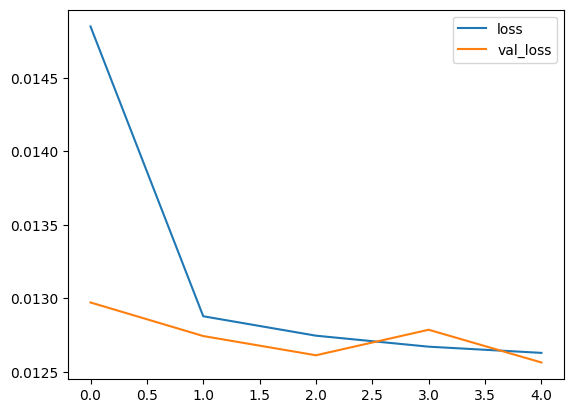

In [ ]:
#note that fitting is very slow here.  LSTM() is not fast because there are many parameters.
model1.fit(training_gen1,
          epochs=5,
          validation_data=validation_gen1,
          callbacks=[early_stop])
losses = pd.DataFrame(model1.history.history)
losses.plot()

In [ ]:
output_frames = model1.predict(validation_gen1)


1648/1648 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step


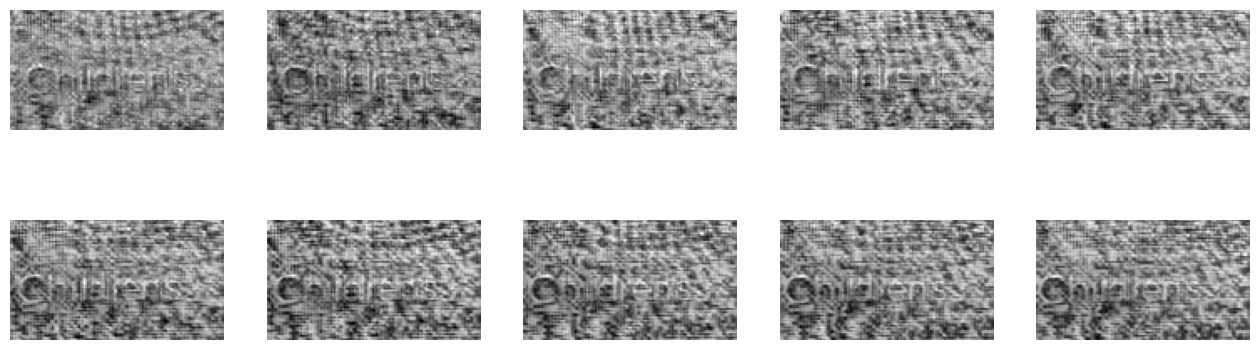

In [ ]:
plt.figure(figsize=(16,5))
for n in range(1,11):
  ax = plt.subplot(2,5,n)
  plt.imshow(output_frames[n+20].reshape(image_height, image_width), cmap=plt.get_cmap('gray'));
  ax.axis('off')

In [ ]:
#here we will use the desired_output (horizontal, vertical components of movement from the gyro)
predict_length = 5      #because LSTM will use this sequence
batch_size = 1
training_set_size = int(0.9 * nTimes)
test_set_size = nTimes - training_set_size
gen2 = TimeseriesGenerator(frames_list, desired_output, length = predict_length, batch_size=batch_size)
training_gen2 = TimeseriesGenerator(frames_list[:training_set_size], desired_output[:training_set_size,:], length = predict_length, batch_size=batch_size)
validation_gen2 = TimeseriesGenerator(frames_list[:-test_set_size], desired_output[:-test_set_size,:], length = predict_length, batch_size=batch_size)
early_stop = EarlyStopping(monitor='val_loss',patience=2)

#note the shape of the output:  (batch_size, predict_length, height, width, colorchannels)
gen2[100][0].shape

(1, 5, 72, 128)

Model: "model2"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 5, 72,     │          0 │ -                 │
│ (InputLayer)        │ 128, 1)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv_lstm2d_1       │ (None, 72, 128,   │        736 │ input_layer[0][0] │
│ (ConvLSTM2D)        │ 4)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ average_pooling2d   │ (None, 8, 14, 4)  │          0 │ conv_lstm2d_1[0]… │
│ (AveragePooling2D)  │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten (Flatten)   │ (None, 448)       │          0 │ average_pooling2… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense1a (Dense)     │ (None, 20)        │      8,980 │ flatten[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense1b (Dense)     │ (None, 20)        │      8,980 │ flatten[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense3a (Dense)     │ (None, 1)         │         21 │ dense1a[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense3b (Dense)     │ (None, 1)         │         21 │ dense1b[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 2)         │          0 │ dense3a[0][0],    │
│ (Concatenate)       │                   │            │ dense3b[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape (Reshape)   │ (None, 2, 1)      │          0 │ concatenate[0][0] │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 18,738 (73.20 KB)

 Trainable params: 18,738 (73.20 KB)

 Non-trainable params: 0 (0.00 B)

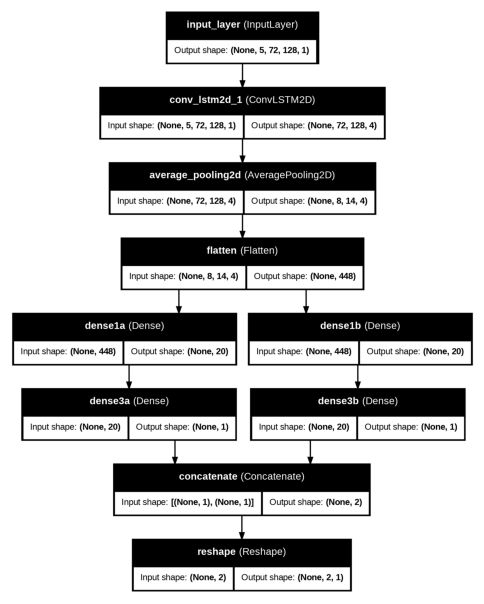

In [ ]:
#build the network len_conv_window = 5            #how many points in the convolution kernel in both x and y directions
n_conv_units = 4              #how many different convolution kernels h_i
n_dense_units = 20
n_sensors = 1                  #this is now grayscale, so only one channel
n_time_images = predict_length
n_batch = 1

#this time we will use the standard Keras interface.  each layer is linked to the one below programmatically
input_layer = Input(shape=(n_time_images, image_height, image_width, n_sensors), name='input_layer')
#convLSTM2D has n_conv_units outputs for each pixel in the image.  padding="same" means output image is same size as input
# channels_last data format says this was in the format height, width channels (not channels, height, width)).
time_space_layer = ConvLSTM2D(filters=n_conv_units, kernel_size=(3,3), data_format='channels_last',
                              padding='same', return_sequences=False, activation='linear')(input_layer)
average_layer = AveragePooling2D(pool_size=(9,9), padding = "valid", data_format = 'channels_last')(time_space_layer)
#sandwich_layer = Dense(n_conv_units, activation = 'sigmoid', name='sandwich')(average_layer)
#average_layer2 = AveragePooling2D(pool_size=(3,3), padding = "valid", data_format = 'channels_last')(sandwich_layer)
flat_layer = Flatten()(average_layer)

#split into two parallel streams
dense1a = Dense(units=n_dense_units, activation='sigmoid', name='dense1a')(flat_layer)
dense1b = Dense(units=n_dense_units, activation='sigmoid', name='dense1b')(flat_layer)
#dense2a = Dense(units=n_dense_units2, activation='sigmoid', name='dense2a')(dense1a)
#dense2b = Dense(units=n_dense_units2, activation='sigmoid', name='dense2b')(dense1b)
dense3a = Dense(units=1, activation='linear', name='dense3a')(dense1a)
dense3b = Dense(units=1, activation='linear', name='dense3b')(dense1b)
concat = Concatenate(axis=1)([dense3a, dense3b])   # put the two streams back together so the training data will work as a numpy array
reshape = Reshape(target_shape=(2,1))(concat)
output_layer = reshape  #the output is the result of the two streams

model2 = Model(inputs = input_layer, outputs = output_layer, name ='model2')  #have to explicitly tell it the inputs and outputs
model2.compile(optimizer='adam', loss='mse')
model2.summary()
#plot_model(model2, show_shapes = True, show_layer_names = True)

plot_model(model2, to_file='model.png', show_shapes=True, show_layer_names=True)

plt.figure(figsize=(6,8))  # Adjust the figure size as needed
plt.imshow(plt.imread('model.png'))
plt.axis('off')
plt.show()



  self._warn_if_super_not_called()



Epoch 1/5
1648/1648 ━━━━━━━━━━━━━━━━━━━━ 17s 8ms/step - loss: 1.0555 - val_loss: 0.9577
Epoch 2/5
1648/1648 ━━━━━━━━━━━━━━━━━━━━ 13s 8ms/step - loss: 0.9557 - val_loss: 0.9698
Epoch 3/5
1648/1648 ━━━━━━━━━━━━━━━━━━━━ 12s 8ms/step - loss: 0.9389 - val_loss: 0.9126
Epoch 4/5
1648/1648 ━━━━━━━━━━━━━━━━━━━━ 14s 8ms/step - loss: 0.8521 - val_loss: 0.8012
Epoch 5/5
1648/1648 ━━━━━━━━━━━━━━━━━━━━ 13s 8ms/step - loss: 0.7523 - val_loss: 0.5928


<Axes: >

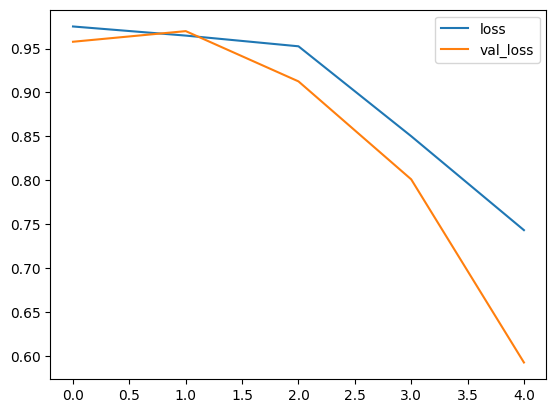

In [ ]:
model2.fit(training_gen2,
          epochs=5,
          validation_data=validation_gen2,
          callbacks=[early_stop])
losses = pd.DataFrame(model2.history.history)
losses.plot()

In [ ]:
predicted_output = model2.predict(gen2)

  self._warn_if_super_not_called()



1832/1832 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step


In [ ]:
#po = np.asarray(predicted_output).reshape(len(predicted_output),2)
po = np.asarray(predicted_output[:,:,0])
dfPredict = pd.DataFrame(data=po)
nPredict,_  = dfPredict.shape

In [ ]:
dfPredict

,0,1
0,-0.084485,0.435342
1,-0.093306,0.420505
2,-0.034826,0.419701
3,-0.007238,0.345999
4,0.007288,0.322729
...,...,...
1827,0.416902,-0.708743
1828,0.315250,-0.695643
1829,0.236670,-0.656111
1830,0.178397,-0.600457


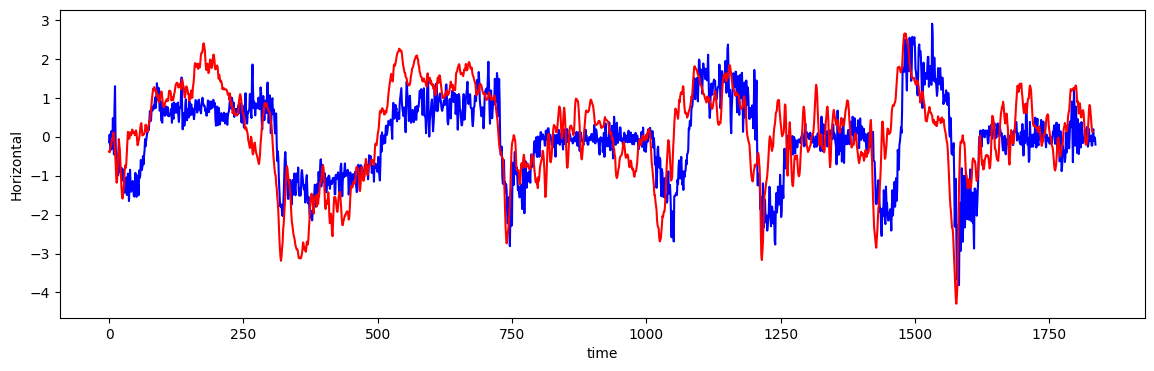

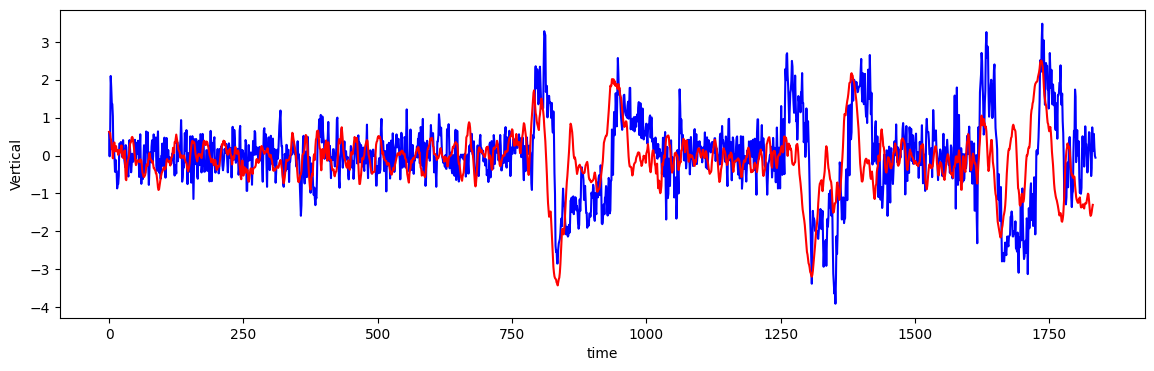

In [ ]:
predict = dfPredict.values   #do not have to do ML or MMSE calculation here
predict -= predict.mean()
predict /= predict.std()    #should not have to do this

plt.figure(figsize=(14,4),linewidth=.1)
plt.plot(desired_output[:,0],'b')  #compare one column at a time
plt.plot(predict[:,0],'r')
plt.ylabel('Horizontal')
plt.xlabel('time');

plt.figure(figsize=(14,4),linewidth=.1)
plt.plot(desired_output[:,1],'b')  #compare one column at a time
plt.plot(predict[:,1],'r')
plt.ylabel('Vertical')
plt.xlabel('time');




In [ ]:
rms_error = np.sqrt(np.sum(np.mean(np.square(predict-desired_output[:nPredict,:]))))
print('Scalar output rms_error {}'.format(rms_error));

Scalar output rms_error 0.991514074139302


Model: "model2"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 5, 72,     │          0 │ -                 │
│ (InputLayer)        │ 128, 1)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv_lstm2d_2       │ (None, 72, 128,   │     11,040 │ input_layer[0][0] │
│ (ConvLSTM2D)        │ 10)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ average_pooling2d_1 │ (None, 24, 42,    │          0 │ conv_lstm2d_2[0]… │
│ (AveragePooling2D)  │ 10)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sandwich (Dense)    │ (None, 24, 42,    │        110 │ average_pooling2… │
│                     │ 10)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ average_pooling2d_2 │ (None, 8, 14, 10) │          0 │ sandwich[0][0]    │
│ (AveragePooling2D)  │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten_1 (Flatten) │ (None, 1120)      │          0 │ average_pooling2… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense1a (Dense)     │ (None, 10)        │     11,210 │ flatten_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense1b (Dense)     │ (None, 10)        │     11,210 │ flatten_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense2a (Dense)     │ (None, 10)        │        110 │ dense1a[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense2b (Dense)     │ (None, 10)        │        110 │ dense1b[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense3a (Dense)     │ (None, 1)         │         11 │ dense2a[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense3b (Dense)     │ (None, 1)         │         11 │ dense2b[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_1       │ (None, 2)         │          0 │ dense3a[0][0],    │
│ (Concatenate)       │                   │            │ dense3b[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape_1 (Reshape) │ (None, 2, 1)      │          0 │ concatenate_1[0]… │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 33,812 (132.08 KB)

 Trainable params: 33,812 (132.08 KB)

 Non-trainable params: 0 (0.00 B)

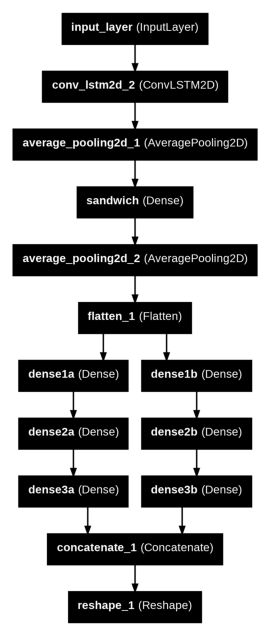

In [ ]:
#build the network len_conv_window = 5            #how many points in the convolution kernel in both x and y directions
n_conv_units = 10              #how many different convolution kernels h_i
n_sensors = 1                  #this is now grayscale, so only one channel
n_time_images = predict_length
n_batch = 1

#this time we will use the standard Keras interface.  each layer is linked to the one below programmatically
input_layer = Input(shape=(n_time_images, image_height, image_width, n_sensors), name='input_layer')
#convLSTM2D has n_conv_units outputs for each pixel in the image.  padding="same" means output image is same size as input
# channels_last data format says this was in the format height, width channels (not channels, height, width)).
time_space_layer = ConvLSTM2D(filters=n_conv_units, kernel_size=(5,5), data_format='channels_last',
                              padding='same', return_sequences=False)(input_layer)
average_layer = AveragePooling2D(pool_size=(3,3), padding = "valid", data_format = 'channels_last')(time_space_layer)
sandwich_layer = Dense(n_conv_units, activation = 'sigmoid', name='sandwich')(average_layer)
average_layer2 = AveragePooling2D(pool_size=(3,3), padding = "valid", data_format = 'channels_last')(sandwich_layer)
flat_layer = Flatten()(average_layer2)

#split into two parallel streams
dense1a = Dense(units=n_conv_units, activation='sigmoid', name='dense1a')(flat_layer)
dense1b = Dense(units=n_conv_units, activation='sigmoid', name='dense1b')(flat_layer)
dense2a = Dense(units=n_conv_units, activation='sigmoid', name='dense2a')(dense1a)
dense2b = Dense(units=n_conv_units, activation='sigmoid', name='dense2b')(dense1b)
dense3a = Dense(units=1, activation='linear', name='dense3a')(dense2a)
dense3b = Dense(units=1, activation='linear', name='dense3b')(dense2b)
concat = Concatenate(axis=1)([dense3a, dense3b])   # put the two streams back together so the training data will work as a numpy array
reshape = Reshape(target_shape=(2,1))(concat)

output_layer = reshape  #the output is the result of the two streams

model3 = Model(inputs = input_layer, outputs = output_layer, name ='model2')  #have to explicitly tell it the inputs and outputs
model3.compile(optimizer='adam', loss='mse')
model3.summary()
plot_model(model3, to_file='model.png', show_shapes=False, show_layer_names=True)

plt.figure(figsize=(6,8))  # Adjust the figure size as needed
plt.imshow(plt.imread('model.png'))
plt.axis('off')
plt.show()



In [ ]:
dfGyro[['wx','wy','wz']].agg(['min','max'])

,wx,wy,wz
min,-0.633504,-0.762773,-0.281728
max,0.563223,0.580719,0.290422


In [ ]:
print(desired_output_horizontal.min())
print(desired_output_horizontal.max())
print(desired_output_vertical.min())
print(desired_output_vertical.max())

-3.811472041205029
2.901772043526544
-3.9110358200845434
3.477142693751339


In [ ]:
threshold_hor = np.percentile(desired_output_horizontal, 90)
threshold_ver = np.percentile(desired_output_vertical, 90)

In [ ]:
labels_hor = (desired_output_horizontal > threshold_hor).astype(int)
labels_ver = (desired_output_vertical > threshold_ver).astype(int)

In [ ]:
print("Still Horizontal:", np.sum(labels_hor==0))
print("Still Vertical:", np.sum(labels_ver==0))
print("Moving Horizontal:", np.sum(labels_hor==1))
print("Moving Vertical:", np.sum(labels_ver==1))

Still Horizontal: 1653
Still Vertical: 1654
Moving Horizontal: 184
Moving Vertical: 183


In [ ]:
dfPredict

,0,1
0,-0.383343,0.623508
1,-0.400427,0.594770
2,-0.287159,0.593212
3,-0.233724,0.450460
4,-0.205587,0.405389
...,...,...
1827,0.587792,-1.592463
1828,0.390902,-1.567091
1829,0.238701,-1.490520
1830,0.125833,-1.382725


In [ ]:
desired_output

array([[-0.14203974,  0.61433608],
       [ 0.05582077, -0.02093982],
       [-0.18238127,  0.59205631],
       ...,
       [-0.07146101,  0.20568902],
       [-0.02087806, -0.01215516],
       [-0.20259262, -0.05642209]])

In [ ]:
# desired_output shape: (nTimes, 2)
# column 0: horizontal  (from wy / std)
# column 1: vertical    (from wx / std)
nTimes, nOutputs = desired_output.shape

In [ ]:
import numpy as np

# 1) Motion magnitude from desired_output (already normalized)
horizontal = desired_output[:, 0]
vertical   = desired_output[:, 1]

print(horizontal)
print(vertical)

motion_mag = np.sqrt(horizontal**2 + vertical**2)

# 2) Choose a threshold (top 20% strongest motion = moving)
threshold = np.percentile(motion_mag, 20)
print("Motion threshold:", threshold)

# 3) Binary label: 1 = moving, 0 = not moving
y_binary = (motion_mag > threshold).astype(int)

print("Frames not moving:", np.sum(y_binary == 0))
print("Frames moving    :", np.sum(y_binary == 1))

[-0.14203974  0.05582077 -0.18238127 ... -0.07146101 -0.02087806
 -0.20259262]
[ 0.61433608 -0.02093982  0.59205631 ...  0.20568902 -0.01215516
 -0.05642209]
Motion threshold: 0.7058835063492337
Frames not moving: 368
Frames moving    : 1469


In [ ]:
# One-hot encoding: 2 outputs
# moving (1)  -> [1, 0]
# still  (0)  -> [0, 1]y_onehot = np.zeros((len(y_binary), 2), dtype=np.float32)
y_onehot = np.zeros((len(y_binary), 2), dtype=np.float32)
y_onehot[y_binary == 1, 0] = 1.0   # moving
y_onehot[y_binary == 0, 1] = 1.0   # not moving

print("y_onehot shape:", y_onehot.shape)
print("Example:", y_binary[0], "->", y_onehot[0])


y_onehot shape: (1837, 2)
Example: 0 -> [0. 1.]


In [ ]:
import numpy as np

frames_array = np.array(frames_list, dtype=np.float32)  # (N, H, W)
frames_array = frames_array[..., np.newaxis]            # (N, H, W, 1)

nTimes, image_height, image_width, n_sensors = frames_array.shape
print("frames_array shape:", frames_array.shape)

# Make sure labels and frames are same length
y_onehot = y_onehot[:nTimes]

frames_array shape: (1837, 72, 128, 1)


In [ ]:
from tensorflow.keras.preprocessing.sequence import TimeseriesGenerator
from tensorflow.keras.callbacks import EarlyStopping

predict_length = 5      # as before
batch_size = 1
training_set_size = int(0.8 * nTimes)
test_set_size = nTimes - training_set_size

# Full generator (for later evaluation)
gen_mvmt = TimeseriesGenerator(frames_array, y_onehot,
                               length=predict_length,
                               batch_size=batch_size)

# Training generator (first 80%)
training_gen_mvmt = TimeseriesGenerator(frames_array[:training_set_size],
                                        y_onehot[:training_set_size],
                                        length=predict_length,
                                        batch_size=batch_size)

# Validation generator (last 20%)
validation_gen_mvmt = TimeseriesGenerator(
    frames_array[-(test_set_size + predict_length):],
    y_onehot[-(test_set_size + predict_length):],
    length=predict_length,
    batch_size=batch_size
)

early_stop = EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)

print("Training batches :", len(training_gen_mvmt))
print("Validation batches:", len(validation_gen_mvmt))


Training batches : 1464
Validation batches: 368


Model: "model_movement"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 5, 72, 128, 1)  │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_lstm2d_3 (ConvLSTM2D)      │ (None, 72, 128, 4)     │           736 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d_3             │ (None, 8, 14, 4)       │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 448)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense1 (Dense)                  │ (None, 20)             │         8,980 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ movement_output (Dense)         │ (None, 2)              │            42 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 9,758 (38.12 KB)

 Trainable params: 9,758 (38.12 KB)

 Non-trainable params: 0 (0.00 B)

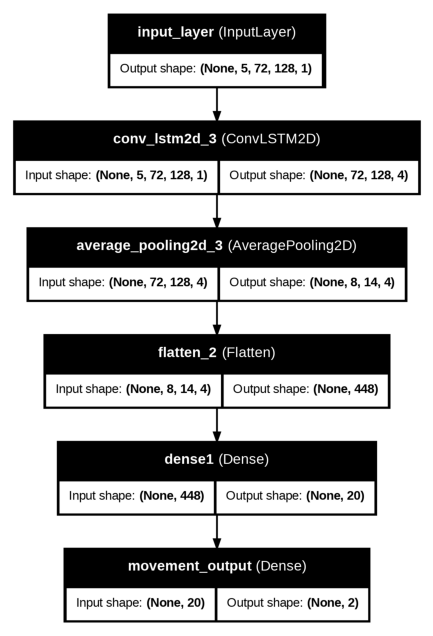

In [ ]:
from tensorflow.keras.models import Model
from tensorflow.keras.layers import (Input, ConvLSTM2D, AveragePooling2D,
                                     Flatten, Dense)
import tensorflow as tf

len_conv_window = 3            # kernel (3x3)
n_conv_units    = 4            # how many ConvLSTM filters
n_dense_units   = 20
n_sensors       = 1
n_time_images   = predict_length

input_layer = Input(shape=(n_time_images, image_height, image_width, n_sensors),
                    name='input_layer')

# ConvLSTM: spatio-temporal feature extractor
time_space_layer = ConvLSTM2D(filters=n_conv_units,
                              kernel_size=(len_conv_window, len_conv_window),
                              data_format='channels_last',
                              padding='same',
                              return_sequences=False,
                              activation='linear')(input_layer)

# Average pooling over space
average_layer = AveragePooling2D(pool_size=(9,9),
                                 padding="valid",
                                 data_format='channels_last')(time_space_layer)

flat_layer = Flatten()(average_layer)

# Dense layers
dense1 = Dense(units=n_dense_units, activation='relu', name='dense1')(flat_layer)

# FINAL OUTPUT: 2 neurons, softmax -> [p(moving), p(not_moving)]
output_layer = Dense(units=2,
                     activation='softmax',
                     name='movement_output')(dense1)

model_mvmt = Model(inputs=input_layer, outputs=output_layer, name='model_movement')

model_mvmt.compile(
    optimizer='adam',
    loss='categorical_crossentropy',    # because labels are one-hot
    metrics=['accuracy']
)

model_mvmt.summary()

plot_model(model_mvmt, to_file='model.png', show_shapes=True, show_layer_names=True)

plt.figure(figsize=(6,8))  # Adjust the figure size as needed
plt.imshow(plt.imread('model.png'))
plt.axis('off')
plt.show()




  self._warn_if_super_not_called()



Epoch 1/10
1464/1464 ━━━━━━━━━━━━━━━━━━━━ 14s 7ms/step - accuracy: 0.8008 - loss: 0.5227 - val_accuracy: 0.8071 - val_loss: 0.4938
Epoch 2/10
1464/1464 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.7844 - loss: 0.5358 - val_accuracy: 0.8071 - val_loss: 0.4962
Epoch 3/10
1464/1464 ━━━━━━━━━━━━━━━━━━━━ 8s 6ms/step - accuracy: 0.8141 - loss: 0.4865 - val_accuracy: 0.8071 - val_loss: 0.5024
Epoch 4/10
1464/1464 ━━━━━━━━━━━━━━━━━━━━ 9s 6ms/step - accuracy: 0.7990 - loss: 0.5083 - val_accuracy: 0.8071 - val_loss: 0.5055


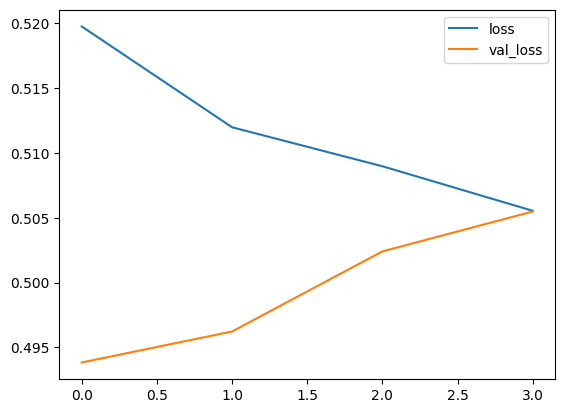

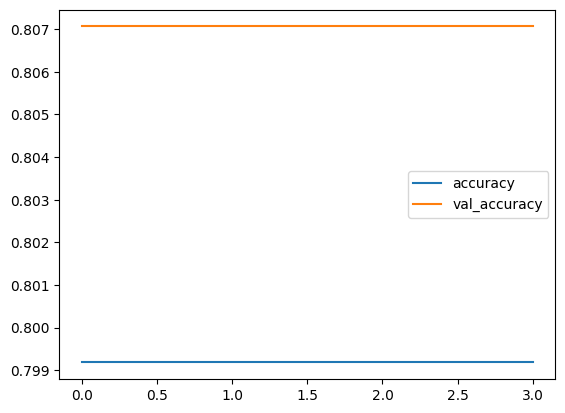

In [ ]:
history = model_mvmt.fit(
    training_gen_mvmt,
    epochs=10,
    validation_data=validation_gen_mvmt,
    callbacks=[early_stop]
)

import pandas as pd
import matplotlib.pyplot as plt

losses = pd.DataFrame(history.history)
losses[['loss','val_loss']].plot()
plt.show()

losses[['accuracy','val_accuracy']].plot()
plt.show()


In [ ]:
import numpy as np
from sklearn.metrics import classification_report

# Predict over full generator
y_pred_prob = model_mvmt.predict(gen_mvmt)   # shape (N - predict_length, 2)
y_pred_class = np.argmax(y_pred_prob, axis=1)  # 0 = moving, 1 = not_moving

# True labels for the same time indices
y_true_binary = y_binary[predict_length:]            # 1 = moving, 0 = not_moving
y_true_class  = np.where(y_true_binary == 1, 0, 1)   # map to our [moving=0, not_moving=1]

print(classification_report(
    y_true_class,
    y_pred_class,
    target_names=['moving', 'not_moving']
))


  self._warn_if_super_not_called()



1832/1832 ━━━━━━━━━━━━━━━━━━━━ 5s 2ms/step


  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))

  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))

  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



              precision    recall  f1-score   support

      moving       0.80      1.00      0.89      1467
  not_moving       0.00      0.00      0.00       365

    accuracy                           0.80      1832
   macro avg       0.40      0.50      0.44      1832
weighted avg       0.64      0.80      0.71      1832



In [ ]:
po = np.asarray(y_pred_prob[:, 0])     # class 0 column
dfPredict = pd.DataFrame(data=po)
nPredict,_  = dfPredict.shape

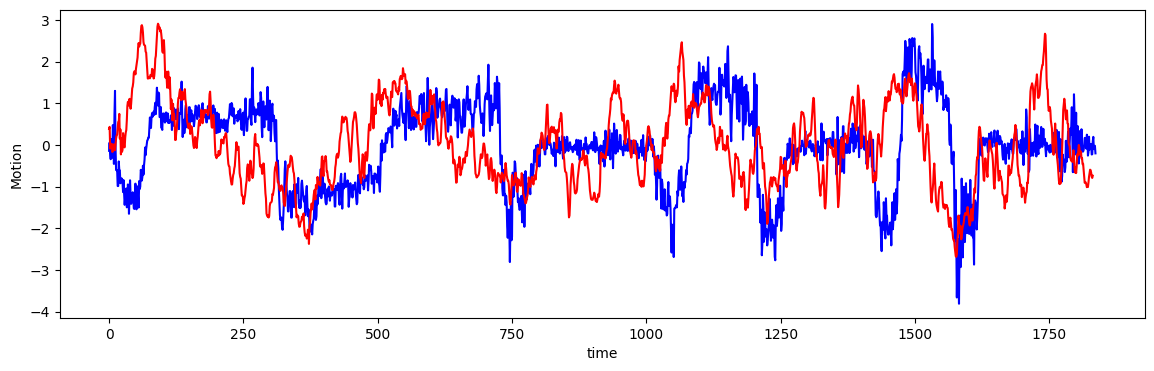

In [ ]:
predict = dfPredict.values   #do not have to do ML or MMSE calculation here
predict -= predict.mean()
predict /= predict.std()    #should not have to do this

plt.figure(figsize=(14,4),linewidth=.1)
plt.plot(desired_output[:,0],'b')  #compare one column at a time
plt.plot(predict[:,0],'r')
plt.ylabel('Motion')
plt.xlabel('time');

In [ ]:
import numpy as np

# 1) Horizontal & vertical components from desired_output
horizontal = desired_output[:, 0]
vertical   = desired_output[:, 1]

hor_abs = np.abs(horizontal)
ver_abs = np.abs(vertical)

# 2) Choose thresholds (20th percentile for each component)
thr_h = np.percentile(hor_abs, 20)
thr_v = np.percentile(ver_abs, 20)

# 3) Binary label: moving if EITHER component is above its own threshold
y_binary = ((hor_abs > thr_h) | (ver_abs > thr_v)).astype(int)

print("Frames not moving:", np.sum(y_binary == 0))
print("Frames moving    :", np.sum(y_binary == 1))

y_onehot = np.zeros((len(y_binary), 2), dtype=np.float32)
y_onehot[y_binary == 1, 0] = 1.0   # moving
y_onehot[y_binary == 0, 1] = 1.0   # not moving

print("y_onehot shape:", y_onehot.shape)
print("Example:", y_binary[0], "->", y_onehot[0])

frames_array = np.array(frames_list, dtype=np.float32)
frames_array = frames_array[..., np.newaxis]

nTimes, image_height, image_width, n_sensors = frames_array.shape
print("frames_array shape:", frames_array.shape)

# to make sure labels and frames are same length
y_onehot = y_onehot[:nTimes]

from tensorflow.keras.preprocessing.sequence import TimeseriesGenerator
from tensorflow.keras.callbacks import EarlyStopping

predict_length = 5
batch_size = 1
training_set_size = int(0.8 * nTimes)
test_set_size = nTimes - training_set_size

gen_mvmt = TimeseriesGenerator(frames_array, y_onehot,
                               length=predict_length,
                               batch_size=batch_size)

training_gen_mvmt = TimeseriesGenerator(frames_array[:training_set_size],
                                        y_onehot[:training_set_size],
                                        length=predict_length,
                                        batch_size=batch_size)

validation_gen_mvmt = TimeseriesGenerator(
    frames_array[-(test_set_size + predict_length):],
    y_onehot[-(test_set_size + predict_length):],
    length=predict_length,
    batch_size=batch_size
)

early_stop = EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)

print("Training batches :", len(training_gen_mvmt))
print("Validation batches:", len(validation_gen_mvmt))


from sklearn.metrics import classification_report

# Predict over full generator
y_pred_prob  = model_mvmt.predict(gen_mvmt)
y_pred_class = np.argmax(y_pred_prob, axis=1)  # 0=moving, 1=not_moving

# True labels aligned with generator output
y_true_onehot = y_onehot[predict_length:]          # generator skips first predict_length
y_true_class  = np.argmax(y_true_onehot, axis=1)   # 0=moving, 1=not_moving

print(classification_report(
    y_true_class,
    y_pred_class,
    target_names=['moving', 'not_moving']
))


  self._warn_if_super_not_called()



Frames not moving: 14
Frames moving    : 1823
y_onehot shape: (1837, 2)
Example: 1 -> [1. 0.]
frames_array shape: (1837, 72, 128, 1)
Training batches : 1464
Validation batches: 368
1832/1832 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step


  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))

  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))

  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



              precision    recall  f1-score   support

      moving       0.99      1.00      1.00      1819
  not_moving       0.00      0.00      0.00        13

    accuracy                           0.99      1832
   macro avg       0.50      0.50      0.50      1832
weighted avg       0.99      0.99      0.99      1832



In [ ]:
%%shell
jupyter nbconvert --to html /content/EECS253_2025_Lecture10.ipynb

[NbConvertApp] Converting notebook /content/EECS253_2025_Lecture10.ipynb to html
[NbConvertApp] WARNING | Alternative text is missing on 15 image(s).
[NbConvertApp] Writing 2778693 bytes to /content/EECS253_2025_Lecture10.html


In [ ]:
nTimes, nOutputs = desired_output.shape
motion = np.sqrt(wx**2 + wy**2 + wz**2)
threshold = np.percentile(motion, 90)

print("Threshold =", threshold)

In [ ]:
labels = (motion > threshold).astype(int)

In [ ]:
print("Still:", np.sum(labels==0))
print("Moving:", np.sum(labels==1))